# Exercise 4 – CNN Width and Depth Experiments

Compare CNN capacity and validation performance by varying width and depth on CIFAR-10. Each configuration is trained with three initialization/data-order seeds on the same seed-42 training/validation split. The official test partition is not loaded or evaluated in this exercise.

## 1. Experiment design

The width study uses two convolutional stages, one convolution per stage, with 16/32, 32/64, or 64/128 filters. The depth study uses 32 filters per convolution and exactly one, two or three convolutional layers. Every depth model has two max-pooling operations after its convolutions, so the classifier receives an 8 by 8 feature map in every case. The pooling schedule stays fixed while the number of convolutional layers changes.

The 32/64 width model has the same architecture as the Exercise 2 CNN. All configurations share the same optimizer, learning rate, batch size, epoch count, and fixed data split.


## 2. Imports and reproducibility

The training split uses seed 42 in every run. Seeds 42, 43, and 44 vary model initialization and shuffled training order while holding the split fixed. Reduce `SEEDS` to `[42]` in the configuration cell for a shorter run.

In [1]:
import json
import sys
import random
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from IPython.display import Markdown, display

SPLIT_SEED = 42
SEEDS = [42, 43, 44]

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SPLIT_SEED)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
DATA_DIR = PROJECT_ROOT / "data"
CIFAR_DIR = DATA_DIR / "cifar-10-batches-py"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "exercise_4"
MODEL_DIR = ARTIFACT_DIR / "models"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
download = not (DATA_DIR / "cifar-10-batches-py").exists()
DOWNLOAD_DATA = download
print("Project:", PROJECT_ROOT)
print("Device:", DEVICE)
if DEVICE.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))
else: print("WARNING: CUDA is unavailable; Exercise 4 setup is on CPU.")
print("Training seeds:", SEEDS, "| split seed:", SPLIT_SEED)


Python: D:\AI ML\AI-ML-assessment-cifar10-project\.venv\Scripts\python.exe
PyTorch: 2.14.1+cu126
CUDA available: True
Project: D:\AI ML\AI-ML-assessment-cifar10-project
Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Training seeds: [42, 43, 44] | split seed: 42


## 3. Training data and preprocessing

Use the shared CIFAR-10 channel means and standard deviations. Only the official training partition is constructed here.

In [2]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 1e-3
NUM_WORKERS = 0
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(CIFAR_MEAN, CIFAR_STD)])
train_val_dataset = datasets.CIFAR10(root=str(DATA_DIR), train=True, download=download, transform=transform)
assert len(train_val_dataset) == 50_000
print("Training examples available:", len(train_val_dataset))
print("Classes:", train_val_dataset.classes)


Training examples available: 50000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 4. Shared 45,000/5,000 split

This is the same seed-42 permutation and indexing method used in Exercises 1 and 2. The split is generated once and reused for every seed and configuration.

In [3]:
split_indices = torch.randperm(50_000, generator=torch.Generator().manual_seed(42)).tolist()
train_dataset = Subset(train_val_dataset, split_indices[:45_000])
val_dataset = Subset(train_val_dataset, split_indices[45_000:])
assert len(train_dataset) == 45_000 and len(val_dataset) == 5_000
print(f"Training: {len(train_dataset):,}; validation: {len(val_dataset):,}")


Training: 45,000; validation: 5,000


## 5. Training settings and loaders

These settings match Exercises 1 and 2. Each training loader gets a dedicated generator seeded by the run seed; validation order remains fixed.

In [4]:
loader_args = {"batch_size":BATCH_SIZE,"num_workers":NUM_WORKERS,"pin_memory":DEVICE.type == "cuda"}
def make_train_loader(seed):
    return DataLoader(train_dataset, shuffle=True, generator=torch.Generator().manual_seed(seed), **loader_args)
train_eval_loader = DataLoader(train_dataset, shuffle=False, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)


## 6. Architecture definitions and complexity measures

Width models use two convolutional layers. Depth models use exactly one, two or three convolutional layers, followed by the same two max-pooling operations in every model. This keeps the final feature map at 8 by 8 for all depth configurations. MACs count multiply-accumulates in convolutional and linear layers for one 32×32 image; pooling, activations and bias additions are excluded. FLOPs can be approximated as twice the MAC count.


In [5]:
class WidthCNN(nn.Module):
    def __init__(self, first_filters, second_filters):
        super().__init__()
        self.conv1 = nn.Conv2d(3, first_filters, 3, padding=1)
        self.conv2 = nn.Conv2d(first_filters, second_filters, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc = nn.Linear(second_filters * 8 * 8, 10)
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        return self.fc(torch.flatten(x, 1))

class DepthCNN(nn.Module):
    def __init__(self, num_layers, filters=32):
        super().__init__()
        if num_layers not in (1, 2, 3):
            raise ValueError("num_layers must be 1, 2, or 3")
        self.convs = nn.ModuleList()
        in_channels = 3
        for _ in range(num_layers):
            self.convs.append(nn.Conv2d(in_channels, filters, 3, padding=1))
            in_channels = filters
        self.pool = nn.MaxPool2d(2)
        self.fc = nn.Linear(filters * 8 * 8, 10)
    def forward(self, x):
        for conv in self.convs:
            x = F.relu(conv(x))
        x = self.pool(self.pool(x))
        return self.fc(torch.flatten(x, 1))

def build_model(spec):
    if spec["group"] == "width":
        return WidthCNN(spec["first_filters"], spec["second_filters"])
    return DepthCNN(spec["num_layers"], filters=32)

def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def count_macs_per_image(model):
    macs = {"total":0}
    handles = []
    def conv_hook(module, inputs, output):
        per_output = (module.in_channels // module.groups) * module.kernel_size[0] * module.kernel_size[1]
        macs["total"] += (output.numel() // output.shape[0]) * per_output
    def linear_hook(module, inputs, output):
        macs["total"] += (output.numel() // output.shape[0]) * module.in_features
    for layer in model.modules():
        if isinstance(layer, nn.Conv2d): handles.append(layer.register_forward_hook(conv_hook))
        if isinstance(layer, nn.Linear): handles.append(layer.register_forward_hook(linear_hook))
    model.eval()
    with torch.no_grad(): model(torch.zeros(1,3,32,32))
    for handle in handles: handle.remove()
    return macs["total"]


## 7. Width configurations

All width models have two convolutional layers and two pooling operations. The baseline-width model matches the Exercise 2 CNN.

In [6]:
WIDTH_EXPERIMENTS = [
 {"name":"width_narrow_16_32","display_name":"Narrow CNN","group":"width","order":0,"first_filters":16,"second_filters":32,"filters":"16/32","conv_layers":2},
 {"name":"width_baseline_32_64","display_name":"Baseline-width CNN","group":"width","order":1,"first_filters":32,"second_filters":64,"filters":"32/64","conv_layers":2},
 {"name":"width_wide_64_128","display_name":"Wide CNN","group":"width","order":2,"first_filters":64,"second_filters":128,"filters":"64/128","conv_layers":2},
]


## 8. Depth configurations

The shallow, medium, and deep models contain exactly one, two, and three convolutional layers, respectively. All convolutions use 32 filters. Every model uses the same two max-pooling operations after the convolutional layers.


In [7]:
DEPTH_EXPERIMENTS = [
 {"name":"depth_shallow_32","display_name":"Shallow CNN","group":"depth","order":3,"num_layers":1,"filters":"32","conv_layers":1},
 {"name":"depth_medium_32","display_name":"Medium CNN","group":"depth","order":4,"num_layers":2,"filters":"32","conv_layers":2},
 {"name":"depth_deep_32","display_name":"Deep CNN","group":"depth","order":5,"num_layers":3,"filters":"32","conv_layers":3},
]
EXPERIMENTS = WIDTH_EXPERIMENTS + DEPTH_EXPERIMENTS
EXPECTED_PARAMETERS = {"width_narrow_16_32":25578,"width_baseline_32_64":60362,"width_wide_64_128":157578,"depth_shallow_32":21386,"depth_medium_32":30634,"depth_deep_32":39882}
MACS_BY_NAME = {}
for spec in EXPERIMENTS:
    check_model = build_model(spec)
    count = count_trainable_parameters(check_model)
    assert count == EXPECTED_PARAMETERS[spec["name"]], (spec["name"],count)
    MACS_BY_NAME[spec["name"]] = count_macs_per_image(check_model)
    print(spec["display_name"],"| parameters:",f"{count:,}","| MACs/image:",f"{MACS_BY_NAME[spec['name']]:,}")


Narrow CNN

 | parameters: 25,578 | MACs/image: 1,642,496


Baseline-width CNN | parameters: 60,362 | MACs/image: 5,644,288
Wide CNN | parameters: 157,578 | MACs/image: 20,725,760
Shallow CNN | parameters: 21,386 | MACs/image: 905,216
Medium CNN | parameters: 30,634 | MACs/image: 10,342,400
Deep CNN | parameters: 39,882 | MACs/image: 19,779,584


## 9. Training, evaluation, and checkpoint selection

Log online training and validation metrics for every epoch. After each run, compute evaluation-mode training and validation metrics. Save the final checkpoint and the checkpoint with the highest validation accuracy. A CUDA out-of-memory error stops the run without changing batch size or retrying.

In [8]:
criterion = nn.CrossEntropyLoss()
def epoch_metrics(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = correct = sample_count = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, labels in loader:
            try:
                images, labels = images.to(DEVICE,non_blocking=True), labels.to(DEVICE,non_blocking=True)
                if training: optimizer.zero_grad(set_to_none=True)
                logits = model(images)
                loss = criterion(logits,labels)
                if training:
                    loss.backward(); optimizer.step()
                n=labels.size(0); sample_count+=n; loss_sum+=loss.item()*n
                correct+=(logits.argmax(1)==labels).sum().item()
            except torch.cuda.OutOfMemoryError as exc:
                if training: optimizer.zero_grad(set_to_none=True)
                if torch.cuda.is_available(): torch.cuda.empty_cache()
                raise RuntimeError("CUDA out of memory. Run stopped without retry. Reduce BATCH_SIZE, recreate the model and optimizer, then restart.") from exc
    return loss_sum/sample_count,correct/sample_count

def evaluate(model, loader):
    return epoch_metrics(model,loader,optimizer=None)

def run_experiment(spec,seed):
    set_seed(seed)
    model=build_model(spec).to(DEVICE)
    params=count_trainable_parameters(model); macs=MACS_BY_NAME[spec["name"]]
    optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)
    train_loader=make_train_loader(seed)
    history={key:[] for key in ("train_loss","train_accuracy","val_loss","val_accuracy")}
    best_val_accuracy=-1.0; best_epoch=None; best_state=None
    start=time.perf_counter()
    print(f"\n{spec['display_name']} | seed {seed}",flush=True)
    for epoch in range(1,EPOCHS+1):
        train_loss,train_accuracy=epoch_metrics(model,train_loader,optimizer)
        val_loss,val_accuracy=epoch_metrics(model,val_loader)
        history["train_loss"].append(train_loss); history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss); history["val_accuracy"].append(val_accuracy)
        if val_accuracy>best_val_accuracy:
            best_val_accuracy,best_epoch=val_accuracy,epoch
            best_state={key:value.detach().cpu().clone() for key,value in model.state_dict().items()}
        print(f"{spec['display_name']} seed {seed} | epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f}, accuracy {train_accuracy:.4f} | val loss {val_loss:.4f}, accuracy {val_accuracy:.4f}",flush=True)
    elapsed=time.perf_counter()-start
    train_eval_loss,train_eval_accuracy=evaluate(model,train_eval_loader)
    val_eval_loss,val_eval_accuracy=evaluate(model,val_loader)
    stem=f"{spec['name']}_seed_{seed}"
    torch.save({"model_state_dict":model.cpu().state_dict(),"spec":spec,"seed":seed},MODEL_DIR/f"{stem}_final.pth")
    torch.save({"model_state_dict":best_state,"spec":spec,"seed":seed,"best_epoch":best_epoch},MODEL_DIR/f"{stem}_best_validation.pth")
    with (ARTIFACT_DIR/f"{stem}_history.json").open("w",encoding="utf-8") as f: json.dump(history,f,indent=2)
    model.to(DEVICE)
    row={"name":spec["name"],"display_name":spec["display_name"],"group":spec["group"],"order":spec["order"],"seed":seed,"filters":spec["filters"],"conv_layers":spec["conv_layers"],"trainable_parameters":params,"macs_per_image":macs,"final_train_loss":train_eval_loss,"final_train_accuracy":train_eval_accuracy,"final_validation_loss":val_eval_loss,"final_validation_accuracy":val_eval_accuracy,"best_validation_accuracy":best_val_accuracy,"best_epoch":best_epoch,"train_val_accuracy_gap":train_eval_accuracy-val_eval_accuracy,"validation_loss_min_epoch":int(np.argmin(history["val_loss"])+1),"training_seconds":elapsed}
    print(f"{spec['display_name']} seed {seed}: eval train accuracy {train_eval_accuracy:.4f}; eval validation accuracy {val_eval_accuracy:.4f}; best val accuracy {best_val_accuracy:.4f} at epoch {best_epoch}.",flush=True)
    return row,history


## 10. Run configurations across seeds

Run every width and depth configuration for seeds 42, 43, and 44. The baseline-width seed-42 history is checked against Exercise 2 before the remaining runs continue.

In [9]:
RUN_RESULTS = []
RUN_HISTORIES = {}
ex2_results_path = PROJECT_ROOT / "artifacts" / "exercise_2" / "results.json"
ex2_results = json.loads(ex2_results_path.read_text(encoding="utf-8"))
ex2_history = ex2_results["history"]
baseline_spec = next(s for s in EXPERIMENTS if s["name"] == "width_baseline_32_64")
run_plan = [(baseline_spec, 42)]
run_plan += [(spec, seed) for spec in EXPERIMENTS for seed in SEEDS
             if not (spec["name"] == "width_baseline_32_64" and seed == 42)]
progress_path = ARTIFACT_DIR / "experiment_run_progress.json"
RUN_CONFIGURATION = {
    "EPOCHS": EPOCHS,
    "SEEDS": SEEDS,
    "BATCH_SIZE": BATCH_SIZE,
    "LEARNING_RATE": LEARNING_RATE,
}
allow_resume = False
if progress_path.exists():
    saved_progress = json.loads(progress_path.read_text(encoding="utf-8"))
    if isinstance(saved_progress, dict) and saved_progress.get("configuration") == RUN_CONFIGURATION:
        RUN_RESULTS = saved_progress.get("runs", [])
        allow_resume = True
        for spec, seed in run_plan:
            history_path = ARTIFACT_DIR / f"{spec['name']}_seed_{seed}_history.json"
            if history_path.exists():
                RUN_HISTORIES[(spec["name"], seed)] = json.loads(history_path.read_text(encoding="utf-8"))
    else:
        print("Ignoring progress from a different experiment configuration.", flush=True)
if not allow_resume:
    raise RuntimeError(
        "Exercise 4 saved progress is missing or its configuration differs. This notebook is configured not to retrain; restore matching saved runs first."
    )
completed_keys = {(row["name"], row["seed"]) for row in RUN_RESULTS}
expected_keys = {(spec["name"], seed) for spec in EXPERIMENTS for seed in SEEDS}
missing_results = expected_keys - completed_keys
missing_histories = expected_keys - set(RUN_HISTORIES)
if missing_results or missing_histories:
    raise RuntimeError(
        f"Exercise 4 saved runs are incomplete; missing result rows={sorted(missing_results)}, histories={sorted(missing_histories)}. No training was started."
    )

for spec, seed in run_plan:
    key = (spec["name"], seed)
    if key in completed_keys:
        result = next(row for row in RUN_RESULTS if (row["name"], row["seed"]) == key)
        run_history = RUN_HISTORIES[key]
        print(f"Loaded saved result row for {spec['display_name']} seed {seed}.", flush=True)
    else:
        raise RuntimeError(f"Saved Exercise 4 run is missing for {spec['display_name']} seed {seed}; no training was started.")
    if spec["name"] == "width_baseline_32_64" and seed == 42:
        keys = ("train_loss", "train_accuracy", "val_loss", "val_accuracy")
        matches = all(
            [round(v, 4) for v in run_history[k]] == [round(v, 4) for v in ex2_history[k]]
            for k in keys
        )
        print("Exercise 2 / Exercise 4 seed-42 baseline histories match to 4 decimals:", matches)
        if not matches:
            print("WARNING: Exercise 2 and Exercise 4 baseline histories differ at four decimals.")

run_frame = pd.DataFrame(RUN_RESULTS).sort_values(["order", "seed"]).reset_index(drop=True)
run_frame.to_csv(ARTIFACT_DIR / "experiment_runs.csv", index=False)
with (ARTIFACT_DIR / "experiment_runs.json").open("w", encoding="utf-8") as f:
    json.dump(RUN_RESULTS, f, indent=2)

metric_columns = [
    "trainable_parameters", "macs_per_image", "final_train_loss", "final_train_accuracy",
    "final_validation_loss", "final_validation_accuracy", "best_validation_accuracy",
    "best_epoch", "train_val_accuracy_gap", "training_seconds",
]
aggregate_rows = []
for spec in sorted(EXPERIMENTS, key=lambda item: item["order"]):
    subset = run_frame[run_frame["name"] == spec["name"]]
    row = {key: spec[key] for key in ("name", "display_name", "group", "order", "filters", "conv_layers")}
    for metric in metric_columns:
        values = pd.to_numeric(subset[metric], errors="coerce").dropna()
        row[f"{metric}_mean"] = float(values.mean()) if len(values) else None
        row[f"{metric}_std"] = float(values.std(ddof=1)) if len(values) > 1 else (0.0 if len(values) == 1 else None)
    aggregate_rows.append(row)
comparison = pd.DataFrame(aggregate_rows).sort_values("order").reset_index(drop=True)
comparison.to_csv(ARTIFACT_DIR / "experiment_comparison.csv", index=False)
with (ARTIFACT_DIR / "experiment_comparison.json").open("w", encoding="utf-8") as f:
    json.dump(aggregate_rows, f, indent=2)
results_payload = {"seeds": SEEDS, "split_seed": SPLIT_SEED, "epochs": EPOCHS,
                   "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
                   "runs": RUN_RESULTS, "aggregated": aggregate_rows}
with (ARTIFACT_DIR / "experiment_results.json").open("w", encoding="utf-8") as f:
    json.dump(results_payload, f, indent=2)
display(comparison)

Loaded saved result row for Baseline-width CNN seed 42.


Exercise 2 / Exercise 4 seed-42 baseline histories match to 4 decimals: True
Loaded saved result row for Narrow CNN seed 42.


Loaded saved result row for Narrow CNN seed 43.


Loaded saved result row for Narrow CNN seed 44.


Loaded saved result row for Baseline-width CNN seed 43.


Loaded saved result row for Baseline-width CNN seed 44.


... (9 outputs left out)

Loaded saved result row for Deep CNN seed 42.


Loaded saved result row for Deep CNN seed 43.


Loaded saved result row for Deep CNN seed 44.


,name,display_name,group,order,filters,conv_layers,trainable_parameters_mean,trainable_parameters_std,macs_per_image_mean,macs_per_image_std,...,final_validation_accuracy_mean,final_validation_accuracy_std,best_validation_accuracy_mean,best_validation_accuracy_std,best_epoch_mean,best_epoch_std,train_val_accuracy_gap_mean,train_val_accuracy_gap_std,training_seconds_mean,training_seconds_std
0,width_narrow_16_32,Narrow CNN,width,0,16/32,2,25578.0,0.0,1642496.0,0.0,...,0.678400,0.005012,0.690733,0.003055,10.000000,2.000000,0.135607,0.005795,240.561420,1.728513
1,width_baseline_32_64,Baseline-width CNN,width,1,32/64,2,60362.0,0.0,5644288.0,0.0,...,0.686867,0.007204,0.714933,0.002444,7.333333,1.527525,0.231822,0.011285,252.591694,5.903369
2,width_wide_64_128,Wide CNN,width,2,64/128,2,157578.0,0.0,20725760.0,0.0,...,0.704600,0.003816,0.728533,0.003252,6.333333,2.516611,0.255793,0.016132,271.391863,7.476188
3,depth_shallow_32,Shallow CNN,depth,3,32,1,21386.0,0.0,905216.0,0.0,...,0.665667,0.006992,0.672733,0.000902,17.000000,3.000000,0.073289,0.006514,258.267258,2.610644
4,depth_medium_32,Medium CNN,depth,4,32,2,30634.0,0.0,10342400.0,0.0,...,0.693533,0.005217,0.701533,0.003355,10.666667,4.618802,0.137778,0.010060,256.603235,2.048528
5,depth_deep_32,Deep CNN,depth,5,32,3,39882.0,0.0,19779584.0,0.0,...,0.694000,0.001970,0.707533,0.005508,8.666667,2.081666,0.168126,0.004337,257.496112,3.210214


## 11. Validation and complexity visualisations

Accuracy plots compare final-epoch and best-epoch validation accuracy, with means and standard deviations across seeds. Scatter plots show the same two measures with error bars. Loss curves show seed-42 training histories.


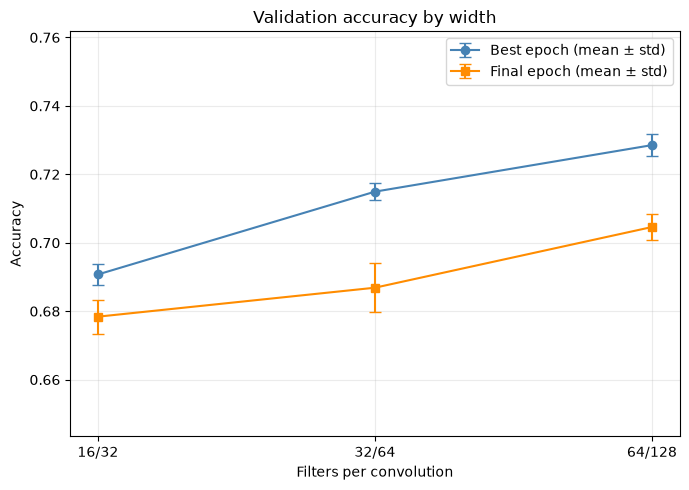

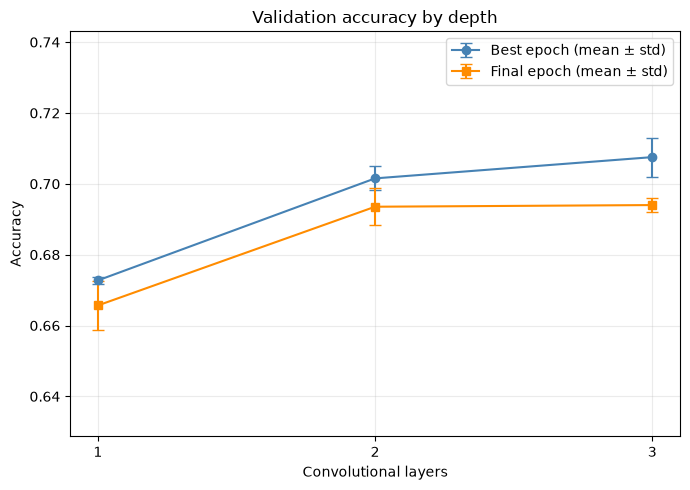

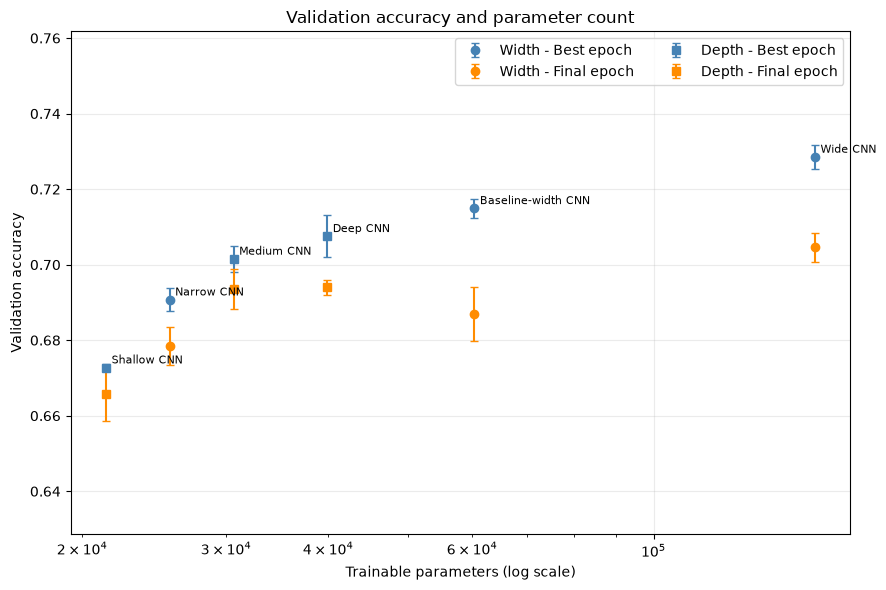

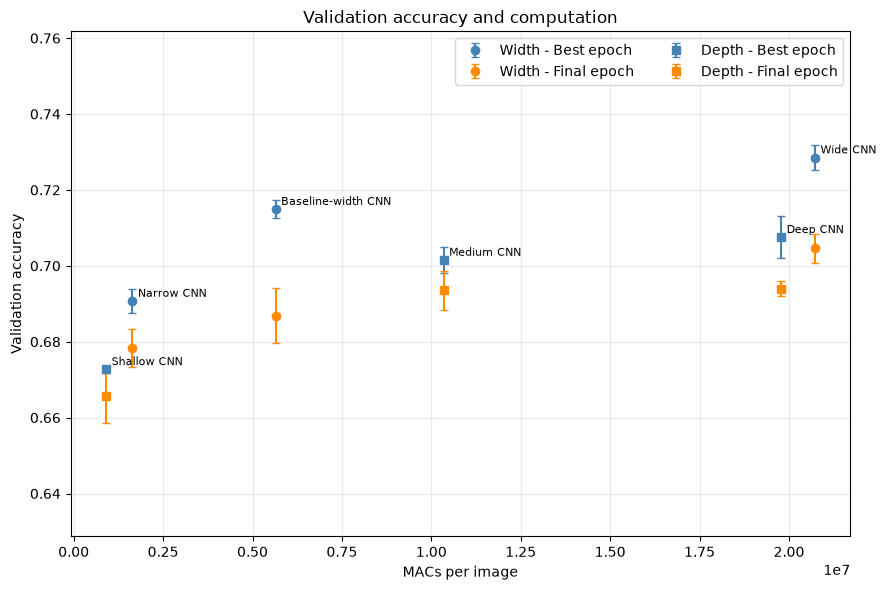

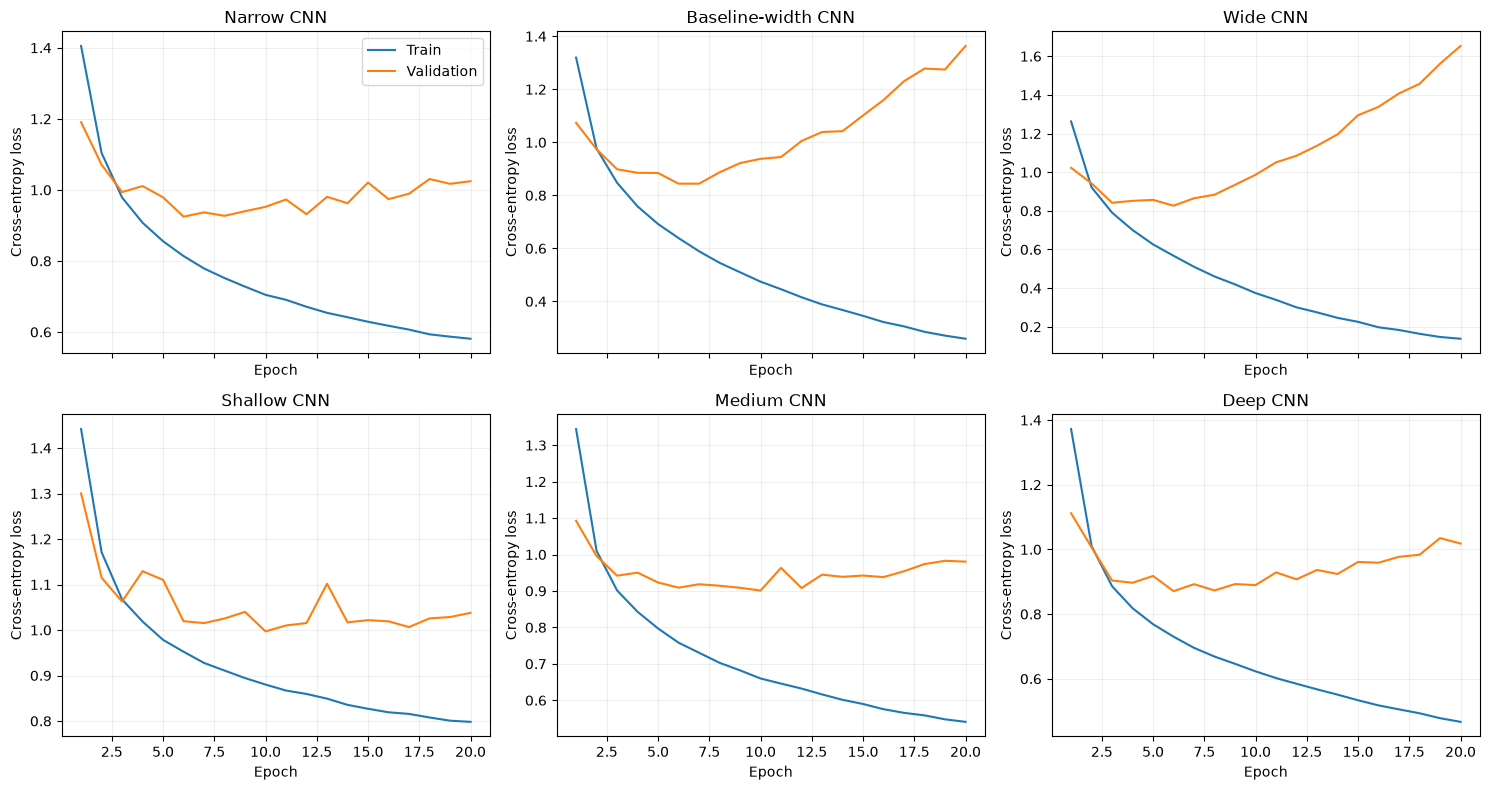

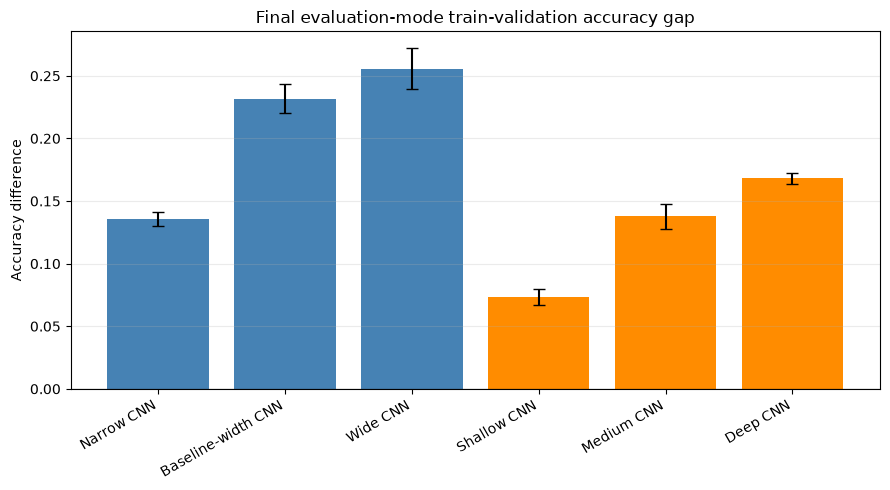

In [10]:
width_rows = comparison[comparison["group"] == "width"].sort_values("order")
depth_rows = comparison[comparison["group"] == "depth"].sort_values("order")
accuracy_series = [
    ("best_validation_accuracy", "Best epoch", "steelblue", "o"),
    ("final_validation_accuracy", "Final epoch", "darkorange", "s"),
]
plus_minus = chr(0x00B1)
def accuracy_limits(rows):
    lows = [rows[f"{metric}_mean"] - rows[f"{metric}_std"] for metric, _, _, _ in accuracy_series]
    highs = [rows[f"{metric}_mean"] + rows[f"{metric}_std"] for metric, _, _, _ in accuracy_series]
    return max(0.0, min(float(values.min()) for values in lows) - 0.03), min(1.0, max(float(values.max()) for values in highs) + 0.03)

fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(len(width_rows))
for metric, label, color, marker in accuracy_series:
    ax.errorbar(x, width_rows[f"{metric}_mean"], yerr=width_rows[f"{metric}_std"],
                label=f"{label} (mean {plus_minus} std)", color=color, marker=marker, capsize=4)
ax.set_xticks(x, width_rows["filters"])
ax.set(title="Validation accuracy by width", xlabel="Filters per convolution", ylabel="Accuracy", ylim=accuracy_limits(width_rows))
ax.legend(); ax.grid(alpha=0.25); fig.tight_layout()
fig.savefig(ARTIFACT_DIR/"validation_accuracy_by_width.png",dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for metric, label, color, marker in accuracy_series:
    ax.errorbar(depth_rows["conv_layers"], depth_rows[f"{metric}_mean"], yerr=depth_rows[f"{metric}_std"],
                label=f"{label} (mean {plus_minus} std)", color=color, marker=marker, capsize=4)
ax.set(title="Validation accuracy by depth", xlabel="Convolutional layers", ylabel="Accuracy", ylim=accuracy_limits(depth_rows))
ax.set_xticks(depth_rows["conv_layers"]); ax.legend(); ax.grid(alpha=0.25); fig.tight_layout()
fig.savefig(ARTIFACT_DIR/"validation_accuracy_by_depth.png",dpi=160); plt.show()

for x_metric, xlabel, filename, title in [
    ("trainable_parameters", "Trainable parameters (log scale)", "validation_accuracy_vs_parameters.png", "Validation accuracy and parameter count"),
    ("macs_per_image", "MACs per image", "validation_accuracy_vs_macs.png", "Validation accuracy and computation"),
]:
    fig, ax = plt.subplots(figsize=(9, 6))
    for group, group_marker in [("width", "o"), ("depth", "s")]:
        rows = comparison[comparison["group"] == group]
        for metric, label, color, _ in accuracy_series:
            ax.errorbar(rows[f"{x_metric}_mean"], rows[f"{metric}_mean"], yerr=rows[f"{metric}_std"],
                        fmt=group_marker, color=color, capsize=3, linestyle="none",
                        label=f"{group.title()} - {label}")
            if metric == "best_validation_accuracy":
                for _, row in rows.iterrows():
                    ax.annotate(row["display_name"], (row[f"{x_metric}_mean"], row[f"{metric}_mean"]),
                                xytext=(4, 3), textcoords="offset points", fontsize=8)
    if x_metric == "trainable_parameters": ax.set_xscale("log")
    ax.set(title=title, xlabel=xlabel, ylabel="Validation accuracy", ylim=accuracy_limits(comparison))
    ax.grid(alpha=0.25); ax.legend(ncol=2); fig.tight_layout(); fig.savefig(ARTIFACT_DIR/filename,dpi=160); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, spec in zip(axes.flat, sorted(EXPERIMENTS,key=lambda item:item["order"])):
    h=RUN_HISTORIES[(spec["name"],42)]; ep=range(1,EPOCHS+1)
    ax.plot(ep,h["train_loss"],label="Train"); ax.plot(ep,h["val_loss"],label="Validation")
    ax.set_title(spec["display_name"]); ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy loss"); ax.grid(alpha=.2)
axes.flat[0].legend(); fig.tight_layout(); fig.savefig(ARTIFACT_DIR/"seed42_loss_curves_2x3.png",dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
x=np.arange(len(comparison))
ax.bar(x,comparison["train_val_accuracy_gap_mean"],yerr=comparison["train_val_accuracy_gap_std"],capsize=4,color=["steelblue" if g=="width" else "darkorange" for g in comparison["group"]])
ax.set_xticks(x,comparison["display_name"],rotation=30,ha="right")
ax.set(title="Final evaluation-mode train-validation accuracy gap",ylabel="Accuracy difference")
ax.axhline(0,color="black",linewidth=.8); ax.grid(axis="y",alpha=.25); fig.tight_layout()
fig.savefig(ARTIFACT_DIR/"train_validation_accuracy_gap.png",dpi=160); plt.show()

## 12. Discussion and conclusion

The summary below is generated from the three-seed measurements. It reports the observed variability and treats small validation differences cautiously.

In [11]:
def row_for(name):
    return comparison.loc[comparison["name"] == name].iloc[0]
def pct(value): return f"{value:.2%}"
def pp(value): return f"{value*100:.2f} pp"
plus_minus = chr(0x00B1)
def pair_text(name_a,name_b):
    a,b=row_for(name_a),row_for(name_b)
    difference=abs(a["best_validation_accuracy_mean"]-b["best_validation_accuracy_mean"])
    combined_sd=np.hypot(a["best_validation_accuracy_std"],b["best_validation_accuracy_std"])
    verdict="exceeds" if difference>combined_sd else "does not exceed"
    return f"The difference between {a['display_name']} and {b['display_name']} is {pp(difference)}; it {verdict} their combined seed SD ({pp(combined_sd)}). With three seeds this is only a heuristic, not a significance test."
width_narrow=row_for("width_narrow_16_32"); width_base=row_for("width_baseline_32_64"); width_wide=row_for("width_wide_64_128")
depth_shallow=row_for("depth_shallow_32"); depth_medium=row_for("depth_medium_32"); depth_deep=row_for("depth_deep_32")
mean_lines=[]
for _,r in comparison.iterrows():
    mean_lines.append(f"- **{r['display_name']}** ({r['filters']} filters; {int(r['conv_layers'])} conv layers): {int(r['trainable_parameters_mean']):,} parameters, {int(r['macs_per_image_mean']):,} MACs/image, best-epoch validation accuracy {pct(r['best_validation_accuracy_mean'])} {plus_minus} {pp(r['best_validation_accuracy_std'])}, final-epoch validation accuracy {pct(r['final_validation_accuracy_mean'])} {plus_minus} {pp(r['final_validation_accuracy_std'])}.")
baseline_keys = ("train_loss", "train_accuracy", "val_loss", "val_accuracy")
baseline_history = RUN_HISTORIES[("width_baseline_32_64", 42)]
baseline_matches = all(
    [round(value, 4) for value in baseline_history[key]] == [round(value, 4) for value in ex2_history[key]]
    for key in baseline_keys
)
seed42_minima=[]
for spec in EXPERIMENTS:
    hist=RUN_HISTORIES[(spec["name"],42)]
    epoch=int(np.argmin(hist["val_loss"])+1)
    seed42_minima.append(f"{spec['display_name']}: epoch {epoch}")
overfit_lines=[]
for spec in sorted(EXPERIMENTS,key=lambda item:item["order"]):
    row=row_for(spec["name"])
    above=sum(RUN_HISTORIES[(spec["name"],seed)]["val_loss"][-1] > min(RUN_HISTORIES[(spec["name"],seed)]["val_loss"]) for seed in SEEDS)
    overfit_lines.append(f"- **{spec['display_name']}**: final train-validation accuracy gap {pp(row['train_val_accuracy_gap_mean'])} {plus_minus} {pp(row['train_val_accuracy_gap_std'])}; final validation loss ended above its minimum in {above}/{len(SEEDS)} seeds.")
width_best_gain_1=width_base["best_validation_accuracy_mean"]-width_narrow["best_validation_accuracy_mean"]
width_best_gain_2=width_wide["best_validation_accuracy_mean"]-width_base["best_validation_accuracy_mean"]
width_final_gain_1=width_base["final_validation_accuracy_mean"]-width_narrow["final_validation_accuracy_mean"]
width_final_gain_2=width_wide["final_validation_accuracy_mean"]-width_base["final_validation_accuracy_mean"]
width_gap_growth=width_wide["train_val_accuracy_gap_mean"]-width_narrow["train_val_accuracy_gap_mean"]
width_mac_ratio=width_wide["macs_per_image_mean"]/width_narrow["macs_per_image_mean"]
depth_gain_1=depth_medium["best_validation_accuracy_mean"]-depth_shallow["best_validation_accuracy_mean"]
depth_gain_2=depth_deep["best_validation_accuracy_mean"]-depth_medium["best_validation_accuracy_mean"]
depth_1_2_combined_sd=np.hypot(depth_shallow["best_validation_accuracy_std"],depth_medium["best_validation_accuracy_std"])
depth_2_3_combined_sd=np.hypot(depth_medium["best_validation_accuracy_std"],depth_deep["best_validation_accuracy_std"])
depth_1_2_exceeds=abs(depth_gain_1)>depth_1_2_combined_sd
depth_2_3_exceeds=abs(depth_gain_2)>depth_2_3_combined_sd
medium_mac_percent=100*depth_medium["macs_per_image_mean"]/width_wide["macs_per_image_mean"]
medium_parameter_percent=100*depth_medium["trainable_parameters_mean"]/width_wide["trainable_parameters_mean"]
deep_mac_percent=100*depth_deep["macs_per_image_mean"]/width_wide["macs_per_image_mean"]
deep_parameter_percent=100*depth_deep["trainable_parameters_mean"]/width_wide["trainable_parameters_mean"]
wide_best_epochs=[int(np.argmax(RUN_HISTORIES[("width_wide_64_128",seed)]["val_accuracy"])+1) for seed in SEEDS]
wide_val_loss_above=sum(
    RUN_HISTORIES[("width_wide_64_128",seed)]["val_loss"][-1] > min(RUN_HISTORIES[("width_wide_64_128",seed)]["val_loss"])
    for seed in SEEDS
)
wide_best_final_diff=100*(width_wide["best_validation_accuracy_mean"]-width_wide["final_validation_accuracy_mean"])
time_means=comparison["training_seconds_mean"].astype(float)
time_min,time_max=float(time_means.min()),float(time_means.max())

multiplication_sign = chr(0x00D7)
analysis=f"""### Results across seeds

{chr(10).join(mean_lines)}

### Overfitting pattern

{chr(10).join(overfit_lines)} These gaps compare evaluation-mode training accuracy with validation accuracy at the final epoch; the loss check uses each seed's recorded validation-loss history.

### Conclusions

- **Width:** Best-epoch validation gains shrink from Narrow to Baseline ({pp(width_best_gain_1)}) and Baseline to Wide ({pp(width_best_gain_2)}). Final-epoch gains instead grow ({pp(width_final_gain_1)} then {pp(width_final_gain_2)}). Wide reached its best validation accuracy at mean epoch {np.mean(wide_best_epochs):.1f} (seed-specific epochs {wide_best_epochs}); its best-to-final accuracy difference was {pp(wide_best_final_diff)}, and final validation loss was above its minimum in {wide_val_loss_above}/{len(SEEDS)} seeds. The conclusion therefore depends on whether early stopping is applied. The mean train-validation gap grew by {pp(width_gap_growth)} from Narrow to Wide, alongside a {width_mac_ratio:.1f}x increase in MACs.
- **Depth:** Moving from one to two convolutions changed best validation accuracy by {pp(depth_gain_1)}; this {"exceeds" if depth_1_2_exceeds else "does not exceed"} the combined seed SD ({pp(depth_1_2_combined_sd)}). Moving from two to three changed it by {pp(depth_gain_2)}; this {"exceeds" if depth_2_3_exceeds else "does not exceed"} the combined seed SD ({pp(depth_2_3_combined_sd)}). With three seeds this is only a heuristic; the SD excludes split variance because all runs share one split.
- **Computation:** Every convolution runs at 32{multiplication_sign}32 resolution before pooling, so adding depth raises MACs steeply. Deep uses {deep_mac_percent:.1f}% of Wide's MACs with {deep_parameter_percent:.1f}% of its parameters; Medium uses {medium_mac_percent:.1f}% of Wide's MACs with {medium_parameter_percent:.1f}% of its parameters.
- **Runtime:** Mean measured training time per 20-epoch run ranged from {time_min:.1f} to {time_max:.1f} seconds across configurations. This is relatively similar compared with the larger spread in MACs, so MACs are the more informative complexity measure here; wall-clock time also reflects library and hardware overhead.

{pair_text('width_narrow_16_32','width_baseline_32_64')} {pair_text('width_baseline_32_64','width_wide_64_128')} {pair_text('depth_shallow_32','depth_medium_32')} {pair_text('depth_medium_32','depth_deep_32')}

The 32/64 width baseline matches Exercise 2 in architecture and training procedure. Their seed-42 epoch histories match to four decimals: **{baseline_matches}**. On seed 42, validation loss reached its minimum at: {', '.join(seed42_minima)}. The official test partition was not loaded or used in this exercise."""
display(Markdown(analysis))

### Results across seeds

- **Narrow CNN** (16/32 filters; 2 conv layers): 25,578 parameters, 1,642,496 MACs/image, best-epoch validation accuracy 69.07% ± 0.31 pp, final-epoch validation accuracy 67.84% ± 0.50 pp.
- **Baseline-width CNN** (32/64 filters; 2 conv layers): 60,362 parameters, 5,644,288 MACs/image, best-epoch validation accuracy 71.49% ± 0.24 pp, final-epoch validation accuracy 68.69% ± 0.72 pp.
- **Wide CNN** (64/128 filters; 2 conv layers): 157,578 parameters, 20,725,760 MACs/image, best-epoch validation accuracy 72.85% ± 0.33 pp, final-epoch validation accuracy 70.46% ± 0.38 pp.
- **Shallow CNN** (32 filters; 1 conv layers): 21,386 parameters, 905,216 MACs/image, best-epoch validation accuracy 67.27% ± 0.09 pp, final-epoch validation accuracy 66.57% ± 0.70 pp.
- **Medium CNN** (32 filters; 2 conv layers): 30,634 parameters, 10,342,400 MACs/image, best-epoch validation accuracy 70.15% ± 0.34 pp, final-epoch validation accuracy 69.35% ± 0.52 pp.
- **Deep CNN** (32 filters; 3 conv layers): 39,882 parameters, 19,779,584 MACs/image, best-epoch validation accuracy 70.75% ± 0.55 pp, final-epoch validation accuracy 69.40% ± 0.20 pp.

### Overfitting pattern

- **Narrow CNN**: final train-validation accuracy gap 13.56 pp ± 0.58 pp; final validation loss ended above its minimum in 3/3 seeds.
- **Baseline-width CNN**: final train-validation accuracy gap 23.18 pp ± 1.13 pp; final validation loss ended above its minimum in 3/3 seeds.
- **Wide CNN**: final train-validation accuracy gap 25.58 pp ± 1.61 pp; final validation loss ended above its minimum in 3/3 seeds.
- **Shallow CNN**: final train-validation accuracy gap 7.33 pp ± 0.65 pp; final validation loss ended above its minimum in 3/3 seeds.
- **Medium CNN**: final train-validation accuracy gap 13.78 pp ± 1.01 pp; final validation loss ended above its minimum in 3/3 seeds.
- **Deep CNN**: final train-validation accuracy gap 16.81 pp ± 0.43 pp; final validation loss ended above its minimum in 3/3 seeds. These gaps compare evaluation-mode training accuracy with validation accuracy at the final epoch; the loss check uses each seed's recorded validation-loss history.

### Conclusions

- **Width:** Best-epoch validation gains shrink from Narrow to Baseline (2.42 pp) and Baseline to Wide (1.36 pp). Final-epoch gains instead grow (0.85 pp then 1.77 pp). Wide reached its best validation accuracy at mean epoch 6.3 (seed-specific epochs [6, 9, 4]); its best-to-final accuracy difference was 239.33 pp, and final validation loss was above its minimum in 3/3 seeds. The conclusion therefore depends on whether early stopping is applied. The mean train-validation gap grew by 12.02 pp from Narrow to Wide, alongside a 12.6x increase in MACs.
- **Depth:** Moving from one to two convolutions changed best validation accuracy by 2.88 pp; this exceeds the combined seed SD (0.35 pp). Moving from two to three changed it by 0.60 pp; this does not exceed the combined seed SD (0.64 pp). With three seeds this is only a heuristic; the SD excludes split variance because all runs share one split.
- **Computation:** Every convolution runs at 32×32 resolution before pooling, so adding depth raises MACs steeply. Deep uses 95.4% of Wide's MACs with 25.3% of its parameters; Medium uses 49.9% of Wide's MACs with 19.4% of its parameters.
- **Runtime:** Mean measured training time per 20-epoch run ranged from 240.6 to 271.4 seconds across configurations. This is relatively similar compared with the larger spread in MACs, so MACs are the more informative complexity measure here; wall-clock time also reflects library and hardware overhead.

The difference between Narrow CNN and Baseline-width CNN is 2.42 pp; it exceeds their combined seed SD (0.39 pp). With three seeds this is only a heuristic, not a significance test. The difference between Baseline-width CNN and Wide CNN is 1.36 pp; it exceeds their combined seed SD (0.41 pp). With three seeds this is only a heuristic, not a significance test. The difference between Shallow CNN and Medium CNN is 2.88 pp; it exceeds their combined seed SD (0.35 pp). With three seeds this is only a heuristic, not a significance test. The difference between Medium CNN and Deep CNN is 0.60 pp; it does not exceed their combined seed SD (0.64 pp). With three seeds this is only a heuristic, not a significance test.

The 32/64 width baseline matches Exercise 2 in architecture and training procedure. Their seed-42 epoch histories match to four decimals: **True**. On seed 42, validation loss reached its minimum at: Narrow CNN: epoch 6, Baseline-width CNN: epoch 7, Wide CNN: epoch 6, Shallow CNN: epoch 10, Medium CNN: epoch 10, Deep CNN: epoch 6. The official test partition was not loaded or used in this exercise.